# 02 · Cross-correlograms and functional connectivity — **Python / pynapple & SpikeInterface**

The brain is a network of neurons, and we can study it through its **connectivity**:

- **structural connectivity** is the physical wiring: which neuron makes a synapse onto which
  other one.
- **functional connectivity** is the part of this wiring that is **active**: which neurons
  influence each other, here and now. It can change within seconds, with the state of the animal
  or the task.

With extracellular recordings we cannot see the synapses, but we can see their effect on the spike
trains: if neuron $i$ excites neuron $j$, then $j$ fires more often a few milliseconds after $i$.
The **cross-correlogram** (CCG) measures exactly this, and it is the classic, "gold standard" tool
to infer functional connections from spike trains.

The difficulty is the **scale**: with Neuropixels probes we record hundreds of neurons at once, and
the number of pairs grows as the square of the number of neurons (400 neurons: 160,000 ordered
pairs). Testing each CCG for significance multiplies this cost again. So we need both the
**theory** (what does a CCG count, how do we know a peak is real?) and **efficient tools**.

In this notebook we:

1. build the CCG from its definition, and see three ways to compute it (counting, a sliding dot
   product, the Fourier transform), and what they cost;
2. compute autocorrelograms and cross-correlograms with [pynapple](https://pynapple.org), and learn
   to read them;
3. see how a shared response to a stimulus creates correlations;
4. correct the CCG with jittered spike trains, and test the significance of a connection;
5. scan **all pairs** of a recording with [SpikeInterface](https://spikeinterface.readthedocs.io),
   build a connectivity matrix, and (advanced) compare the networks between the blocks of the task.

**Dataset.** Session `156131_20191112-probe0` of the same study as notebook 01
([Calvigioni, Fuzik, Le Merre et al., 2023](https://doi.org/10.1038/s41593-023-01367-8)): a
Vglut2-cre mouse, with a Neuropixels probe through the prefrontal cortex (prelimbic, infralimbic,
orbital, anterior cingulate regions) and nearby regions. The session is made of **blocks** of trials:

| Block | Trials | Stimulus |
|---|---|---|
| 1 | 50 | sound (pure tone) |
| 2 | 100 | sound, followed by an optogenetic stimulation of the lateral hypothalamus → lateral habenula pathway (internal aversive) |
| 3 | 50 | sound (as block 1) |
| 4 | 50 | blue noise, followed by an air puff to the eye (external aversive) |
| 5–12 | 340 | optogenetic stimulation only |

## 0. Get the data

The session is on the [DANDI Archive](https://dandiarchive.org), in
[Dandiset 000473](https://dandiarchive.org/dandiset/000473): we use the file
`sub-156131/sub-156131_ses-156131-20191112-probe0_ecephys+ogen.nwb` (5.6 GB).

**Option 1 (recommended): download the file** to a folder of your choice on your computer
(keep it out of the git repo: it is far too big for GitHub). Either:

- in the browser: open the
  [files of the Dandiset](https://dandiarchive.org/dandiset/000473/0.261102.1657/files?location=sub-156131),
  and click the download icon next to the file;
- or in a terminal, from the `python/` folder, with the DANDI command-line tool
  (replace `/path/to/your/data/folder` by the folder where you want to save the file):

  ```bash
  uv run dandi download -o /path/to/your/data/folder "https://api.dandiarchive.org/api/assets/6b424b64-764a-4677-a828-49094420e930/download/"
  ```

Then write the full path to the file in `NWB` in the cell below.

**Option 2 (advanced): stream the file from DANDI**, without downloading it: set `STREAM = True`
below (see section 0 of notebook 01).

In [1]:
# numpy: arrays and maths; matplotlib: figures; pynapple: time series and spike trains;
# h5py: low-level access to the NWB file (an HDF5 file), to read extra unit information
import numpy as np
import matplotlib.pyplot as plt
import pynapple as nap
import h5py
import time
from pathlib import Path

# Option 1: full path to the NWB file you downloaded. Change it to where you saved it.
NWB = "/path/to/your/data/folder/sub-156131_ses-156131-20191112-probe0_ecephys+ogen.nwb"

# Option 2: set to True to stream the file from the DANDI Archive instead
STREAM = True

if not STREAM and not Path(NWB).is_file():
    raise FileNotFoundError(f"No NWB file at {NWB}: set NWB to the downloaded file, or STREAM = True")

if STREAM:
    import remfile
    from dandi.dandiapi import DandiAPIClient

    DANDISET, VERSION = "000473", "0.261102.1657"  # Dandiset id and published version
    ASSET = "sub-156131/sub-156131_ses-156131-20191112-probe0_ecephys+ogen.nwb"
    with DandiAPIClient() as client:
        asset = client.get_dandiset(DANDISET, VERSION).get_asset_by_path(ASSET)
        url = asset.get_content_url(follow_redirects=1, strip_query=True)
    print("streaming from", url)


def open_nwb():
    """Open the NWB file with h5py: the local file, or the remote one if STREAM is True."""
    return h5py.File(remfile.File(url) if STREAM else NWB, "r")

streaming from https://dandiarchive.s3.amazonaws.com/blobs/32e/6d3/32e6d36c-b7dc-4e91-af59-7073696e6f68


**Load the units and keep the good ones**, with the same quality criteria as in notebook 01
(section 2): ISI violation ratio < 0.1, a plausible waveform (FS or RS), and presence ratio > 0.
This time we keep the units of **all the brain regions** crossed by the probe, because we want to
see connections within and between regions. For each unit we also keep its **electrode** and its
**depth** (dorso-ventral coordinate, in mm): two units on nearby electrodes are close in the brain.

In [2]:
if STREAM:
    import pynwb
    data = nap.NWBFile(pynwb.NWBHDF5IO(file=open_nwb()).read())  # remote file
else:
    data = nap.load_file(NWB)  # open the file and list its content

units = data["units"]  # all sorted units (TsGroup)
trials = data["trials"]  # task trials (IntervalSet), with a "Block" column

with open_nwb() as f:  # extra columns of the units table (see notebook 01, section 2)
    isi_fp = f["units/quality"][:, 1]  # ISI violation false-positive rate
    fs = f["units/FS"][:] == 1  # fast-spiking waveform (putative interneuron)
    rs = f["units/RS"][:] == 1  # regular-spiking waveform (putative pyramidal neuron)
    electrode = f["units/electrodes"][:]  # electrode-table row of each unit
    electrodes = f["general/extracellular_ephys/electrodes"]
    location = electrodes["location"][:][electrode].astype(str)  # brain area and layer
    depth = electrodes["DV"][:][electrode]  # dorso-ventral coordinate of the electrode (mm)

cell_type = np.where(fs, "FS", np.where(rs, "RS", "none"))
presence_ratio = (units.count(units.time_support.tot_length() / 100).values > 0).mean(axis=0)
units.set_info(location=location, isi_fp=isi_fp, cell_type=cell_type, electrode=electrode,
               depth=depth, presence_ratio=presence_ratio)

good = units[(units.isi_fp < 0.1) & (units.cell_type != "none") & (units.presence_ratio > 0)]
print("good units:", len(good), "out of", len(units))
print(good.cell_type.value_counts().to_string())
good.location.value_counts()  # how many units per brain area

good units: 239 out of 420
cell_type
RS    204
FS     35


location
ORBm6a    78
PL5       73
DP        22
ILA6a     21
ACAd5     17
ACB       15
AON        9
PL6a       3
OLF        1
Name: count, dtype: int64

## 1. Theoretical background

### 1.1 The definition: counting coincidences

Take two spike trains: a **reference** neuron $i$ and a **target** neuron $j$. Each spike of $i$
is taken in turn as the origin of time, and we place the spikes of $j$ relative to it: $t_j - t_i$.
A negative value means that $j$ fired before $i$, a positive value that $j$ fired after $i$. The CCG
is the **histogram of all these time differences** (the "lags"), in a window (e.g. ±50 ms):

$$ \mathrm{CCG}_{ij}(\tau) = \text{number of pairs of spikes } (t_i, t_j) \text{ with } t_j - t_i \text{ in the bin around } \tau $$

Each count is a **coincidence**: $j$ fired at lag $\tau$ after a spike of $i$. If $i$ excites $j$,
then after many spikes of $i$ there is often a spike of $j$ just after: the CCG has a peak just
after 0. Let's build it on two short simulated spike trains, where neuron $j$ tends to fire
**2 ms after** neuron $i$, plus random spikes of its own.

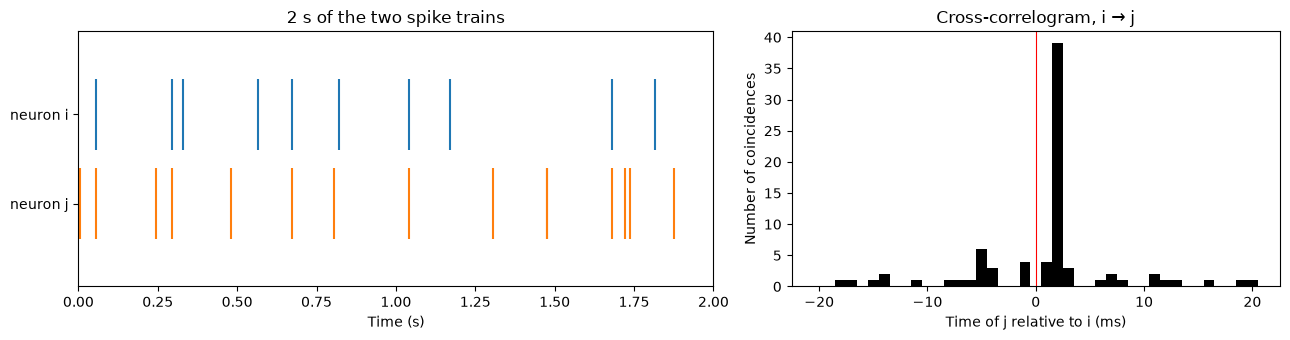

In [ ]:
rng = np.random.default_rng(seed=0)  # random generator with a fixed seed: same result for everyone

# Make some toy example
T_toy = 20.0  # duration of the toy spike trains, in seconds
toy_i = np.sort(rng.uniform(0, T_toy, size=100))  # neuron i: 100 random spikes (5 Hz)
followed = toy_i[rng.random(len(toy_i)) < 0.5]  # about half of the spikes of i...
follow = followed + 0.002 + rng.normal(0, 0.0003, size=len(followed))  # ...are followed by j, 2 ms later
toy_j = np.sort(np.r_[follow, rng.uniform(0, T_toy, size=100)])  # neuron j: followers + random spikes


def spike_time_differences(ref, target, max_lag):
    """All the differences t_target - t_ref that are within ±max_lag (in seconds)."""
    start = np.searchsorted(target, ref - max_lag)  # first target spike after t_ref - max_lag
    stop = np.searchsorted(target, ref + max_lag, side="right")  # last target spike before t_ref + max_lag
    return np.concatenate([target[a:b] - t for t, a, b in zip(ref, start, stop)])


def lag_bins(binsize, windowsize):
    """Bin edges from -windowsize to +windowsize, with bins centered on multiples of binsize
    (one bin is centered on 0), like pynapple."""
    n = int(round(windowsize / binsize))
    return (np.arange(-n, n + 2) - 0.5) * binsize


diffs = spike_time_differences(toy_i, toy_j, max_lag=0.02)  # all the t_j - t_i within ±20 ms
edges = lag_bins(0.001, 0.02)  # 1 ms bins, from -20 to +20 ms
counts, _ = np.histogram(diffs, bins=edges)
centers = (edges[:-1] + edges[1:]) / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5), width_ratios=[1.3, 1])
ax1.eventplot([toy_i, toy_j], colors=["tab:blue", "tab:orange"], lineoffsets=[1, 0], linelengths=0.8)
ax1.set(xlim=(0, 2), yticks=[1, 0], yticklabels=["neuron i", "neuron j"], xlabel="Time (s)",
        title="2 s of the two spike trains")
ax2.bar(centers * 1000, counts, width=1, color="k")
ax2.axvline(0, color="red", lw=0.8)
ax2.set(xlabel="Time of j relative to i (ms)", ylabel="Number of coincidences",
        title="Cross-correlogram, i → j")
plt.tight_layout()
plt.show()

The raster alone does not tell much, but the CCG shows a clear **peak 2 ms after 0**. Outside the
peak, the bins contain the coincidences **by chance**: with random spikes, their number is about
the same in every bin.

**Expected count by chance.** If the two neurons were independent, each spike of $i$ would see on
average $\text{rate}_j \times \text{bin size}$ spikes of $j$ in each bin. So the flat level of the
CCG is

$$ \text{expected count} = N_i \times \text{rate}_j \times \text{bin size} $$

Dividing the CCG by this expected count gives a **normalized CCG**, equal to 1 for independent
neurons, whatever their rates: 2 means "twice as many coincidences as expected by chance".

In [4]:
expected = len(toy_i) * (len(toy_j) / T_toy) * 0.001  # N_i x rate_j x bin size
peak = counts[np.argmin(np.abs(centers - 0.002))]  # count in the 2 ms bin
print(f"expected count by chance: {expected:.2f} per bin")
print(f"count in the 2 ms bin: {peak} ({peak / expected:.0f} times more than by chance)")

expected count by chance: 0.72 per bin
count in the 2 ms bin: 39 (54 times more than by chance)


### 1.2 The CCG as a sliding dot product

Another way to see the CCG: cut time into small bins (here 1 ms) and write each spike train as a
vector of spike counts, $A(t)$ for neuron $i$ and $B(t)$ for neuron $j$ (mostly 0, sometimes 1).
Shift $B$ by a lag $\tau$, multiply it with $A$ bin by bin, and sum:

$$ \mathrm{CCG}_{ij}(\tau) = \sum_t A(t) \, B(t + \tau) $$

A product $A(t) B(t+\tau)$ is 1 exactly when $i$ fired in bin $t$ and $j$ in bin $t + \tau$: a
coincidence at lag $\tau$. This is a **sliding dot product** (the cross-correlation of signal
processing). It gives the same CCG as counting, if we first round the spike times to the bins.

Let's check it on a real pair: **unit 339** (RS, putative pyramidal neuron) and **unit 98** (FS,
putative interneuron), recorded on nearby electrodes in the orbital area (ORBm6a), during the first
10 minutes of the session.

In [5]:
ref_all, target_all = good[339].t, good[98].t  # spike times (s) of the reference and the target
T_short = 600.0  # the first 10 minutes
ref, target = ref_all[ref_all < T_short], target_all[target_all < T_short]
binsize, n_lags = 0.001, 20  # 1 ms bins, lags from -20 to +20 ms
lags = np.arange(-n_lags, n_lags + 1)

# Binned spike trains: number of spikes in each 1 ms bin of the 10 minutes
A = np.bincount((ref / binsize).astype(int), minlength=int(T_short / binsize))
B = np.bincount((target / binsize).astype(int), minlength=int(T_short / binsize))

# Sliding dot product: for each lag, multiply A(t) with B(t + lag) and sum over t
t0 = time.time()
ccg_dot = np.array([np.sum(A[max(0, -k):len(A) - max(0, k)] * B[max(0, k):len(B) - max(0, -k)])
                    for k in lags])
time_dot = time.time() - t0

# Counting, on the spike times rounded to the bins: the same coincidences
t0 = time.time()
binned_diffs = spike_time_differences(np.floor(ref / binsize), np.floor(target / binsize), n_lags)
ccg_count = np.histogram(binned_diffs, bins=np.arange(-n_lags, n_lags + 2) - 0.5)[0]
time_count = time.time() - t0

print("dot product == counting:", np.array_equal(ccg_dot, ccg_count))
print(f"time: dot product {time_dot * 1000:.0f} ms, counting {time_count * 1000:.0f} ms")

dot product == counting: True
time: dot product 17 ms, counting 3 ms


Same CCG. But the dot product visits **every bin of the recording for every lag**: its cost grows
as $T \times M$ (duration in bins × number of lags), even where there is no spike. Counting only
visits the spikes, and the spikes that fall within the window: spike trains are **sparse**
(a neuron at 5 Hz has a spike in 0.5 % of the 1 ms bins), so counting is much faster here.

### 1.3 The Fourier transform

The sliding dot product can also be computed with the **Fourier transform** $\mathcal{F}$: the
cross-correlation of two signals is the inverse transform of the product of their transforms
(one of them complex-conjugated, written $^*$):

$$ \mathrm{CCG}_{ij} = \mathcal{F}^{-1}\left( \mathcal{F}(A)^* \cdot \mathcal{F}(B) \right) $$

With the fast Fourier transform (FFT), this costs about $T \log T$ instead of $T \times M$, and it
gives **all the lags at once**: it is the method of choice for long windows (seconds) or for
continuous signals (e.g. the LFP). The signals must be padded with zeros, so that the end of one
does not wrap around onto the start of the other.

FFT == counting: True
time: FFT 53 ms (all 2097152 lags at once)


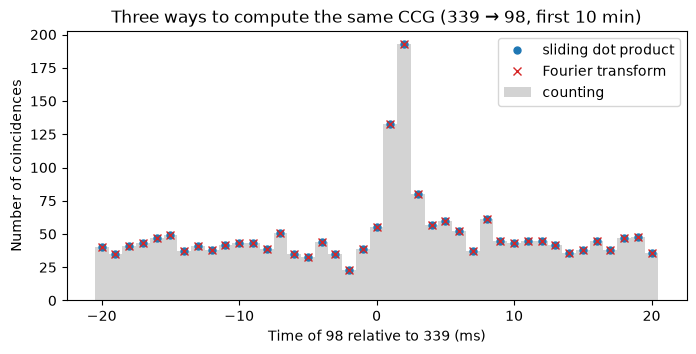

In [6]:
t0 = time.time()
n_fft = 2 ** int(np.ceil(np.log2(2 * len(A))))  # zero padding, to a power of 2 (fast)
full = np.fft.irfft(np.conj(np.fft.rfft(A, n_fft)) * np.fft.rfft(B, n_fft), n_fft)
ccg_fft = np.round(full[lags % n_fft]).astype(int)  # negative lags are at the end of the array
time_fft = time.time() - t0

print("FFT == counting:", np.array_equal(ccg_fft, ccg_count))
print(f"time: FFT {time_fft * 1000:.0f} ms (all {n_fft} lags at once)")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(lags, ccg_count, width=1, color="lightgray", label="counting")
ax.plot(lags, ccg_dot, "o", color="tab:blue", ms=5, label="sliding dot product")
ax.plot(lags, ccg_fft, "x", color="tab:red", ms=6, label="Fourier transform")
ax.set(xlabel="Time of 98 relative to 339 (ms)", ylabel="Number of coincidences",
       title="Three ways to compute the same CCG (339 → 98, first 10 min)")
ax.legend()
plt.show()

The three methods give exactly the same numbers. Which one to use depends on the data:

| Method | Cost | Best for |
|---|---|---|
| counting the spike time differences | number of spikes × spikes in the window | sparse spike trains, short windows (connectivity: ±50 ms) |
| sliding dot product | duration (in bins) × number of lags | (didactic: it is the definition of a cross-correlation) |
| Fourier transform | duration × log(duration), all lags at once | long windows, dense or continuous signals |

In Matthieu's internship, two pipelines were compared on 31 recordings: a counting method built on
SpikeInterface (**countCCG**) and an FFT method in Rust and Julia (**fftCCG**). For spike trains,
counting was the fastest: more than 3 billion pairs in about 10 minutes on a 32-core computer.

### 1.4 What a CCG can show

Before looking at real CCGs, the typical shapes and what they suggest:

- a **sharp peak 1–5 ms after 0**: $j$ fires just after $i$: a putative **excitatory monosynaptic
  connection** $i \to j$ (the delay is the time for the spike to travel and for the synapse to act);
- a **trough 1–10 ms after 0**: $j$ is silenced just after $i$: a putative **inhibitory connection**;
- a **narrow peak exactly at 0**: no synapse is that fast: the two units often share the *same*
  spikes (one neuron detected twice by the spike sorter), or are driven by a common input with the
  same delay;
- a **broad peak** (tens to hundreds of ms): the two neurons are active in the same periods (common
  slow inputs, brain state, a shared response to a stimulus): a **co-modulation**, not a synapse.

A CCG shows a **correlation**, not a connection: a short-latency peak could also come from a third
neuron that drives both units with different delays. This is why we speak of **putative**
connections.

## 2. Autocorrelograms with pynapple

The **autocorrelogram** (ACG) is the CCG of a neuron with itself (the spike itself, at lag 0, is not
counted). It is symmetric, and close to the ISIs of notebook 01: the ISIs only look at the **next**
spike, the ACG at **all** the spikes in the window.

pynapple computes it with `nap.compute_autocorrelogram(group, binsize, windowsize)`:

- with `norm=False`, the result is a **rate** in spikes/s: the rate of the neuron at a time $\tau$
  after one of its spikes;
- with `norm=True` (the default), this rate is divided by the mean rate of the neuron: 1 means
  "as by chance".

The result is a pandas `DataFrame`: one row per bin (the index is the lag, in seconds), one column
per unit. We take three units with different firing patterns.

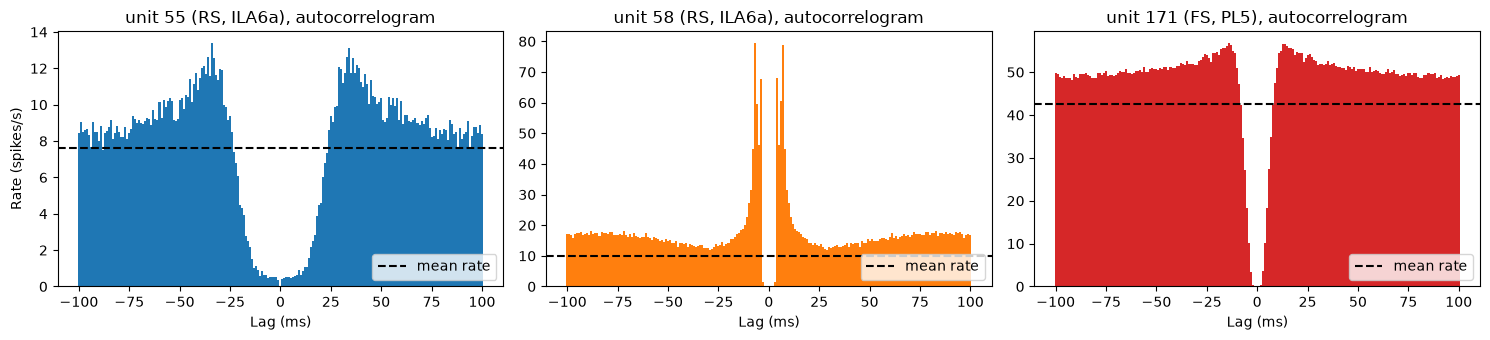

In [7]:
acg_units = {"unit 55 (RS, ILA6a)": 55, "unit 58 (RS, ILA6a)": 58, "unit 171 (FS, PL5)": 171}
acg_colors = ["tab:blue", "tab:orange", "tab:red"]

acg = nap.compute_autocorrelogram(good[list(acg_units.values())], binsize=0.001, windowsize=0.1,
                                  norm=False)  # rate in spikes/s, 1 ms bins, ±100 ms

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for ax, (name, i), color in zip(axes, acg_units.items(), acg_colors):
    ax.bar(acg.index * 1000, acg[i], width=1, color=color)
    ax.axhline(good.rate[i], color="k", ls="--", label="mean rate")
    ax.set(title=f"{name}, autocorrelogram", xlabel="Lag (ms)")
    ax.legend(loc="lower right")
axes[0].set_ylabel("Rate (spikes/s)")
plt.tight_layout()
plt.show()

- All three units have a **gap around 0**: the **refractory period**. A unit without this gap is
  probably a mix of several neurons: the ACG is a classic **quality check** of spike sorting.
- **Unit 55** almost never fires within ~15 ms of one of its spikes, and fires most about 30 ms
  later: a long gap followed by a peak, the signature of a **regular** (or rhythmic) neuron.
- **Unit 58** fires much more than its mean rate in the first ~10 ms after a spike: it fires in
  **bursts** of spikes close together.
- **Unit 171** is a fast-spiking interneuron (about 40 spikes/s), with a short refractory period.

## 3. Cross-correlograms with pynapple

`nap.compute_crosscorrelogram(group, binsize, windowsize)` computes the CCG of every pair of units
of a `TsGroup`. Its columns are pairs `(i, j)`: **unit `j` relative to unit `i`**, as in our
definition. Careful: with one `TsGroup`, pynapple takes the pairs in the order of the unit ids
(`(98, 339)`, not `(339, 98)`). To choose the reference and the target, we give **two groups**:
`(references, targets)`. Let's check that it gives the same CCG as our counting function, for the pair
339 → 98 over the whole session. With `norm=False` it returns a rate, in spikes/s: we multiply by
$N_i \times \text{bin size}$ to get the number of coincidences.

In [8]:
ccg = nap.compute_crosscorrelogram((good[[339]], good[[98]]), binsize=0.001, windowsize=0.05,
                                   norm=False)  # (references, targets): 98 relative to 339
print("columns:", list(ccg.columns))

edges = lag_bins(0.001, 0.05)
centers = (edges[:-1] + edges[1:]) / 2
counts = np.histogram(spike_time_differences(ref_all, target_all, 0.051), bins=edges)[0]
counts_pynapple = ccg[(339, 98)].values * len(ref_all) * 0.001  # rate -> number of coincidences
print("same bins as ours:", np.allclose(ccg.index.values, centers))
print("largest difference with our counts:", np.abs(counts_pynapple - counts).max(),
      "(out of", counts.sum(), "coincidences)")

columns: [(339, 98)]
same bins as ours: True
largest difference with our counts: 24.0 (out of 58794 coincidences)


Same bins, and the same counts except for a few coincidences: the spike time differences that
fall **exactly on a bin edge** (spike times are multiples of the sampling period, 1/30000 s, so this
happens often), which floating-point rounding can put in one bin or the next.

### 3.1 A gallery of cross-correlograms

Here are five pairs of units of this session, each with a typical shape (section 1.4). We use the
normalized CCG (`norm=True`): 1 = as many coincidences as expected by chance. We draw each pair at
two time scales.

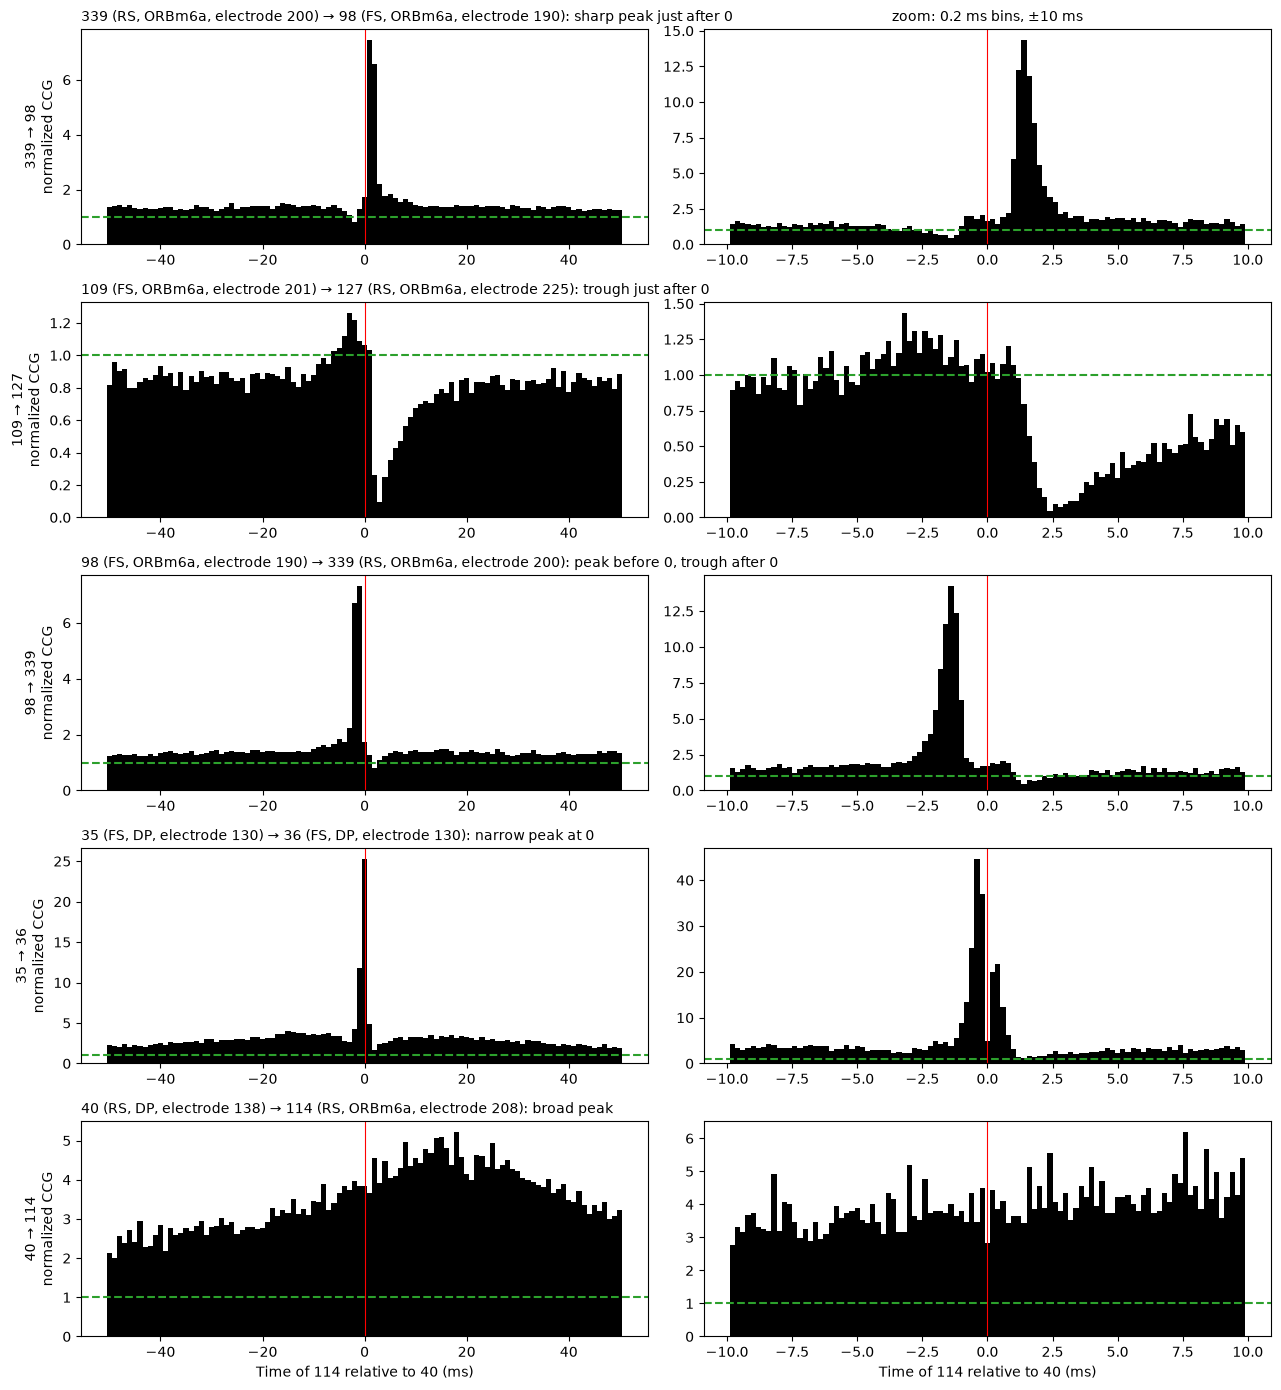

In [9]:
gallery = [  # (reference, target, what we see)
    (339, 98, "sharp peak just after 0"),
    (109, 127, "trough just after 0"),
    (98, 339, "peak before 0, trough after 0"),
    (35, 36, "narrow peak at 0"),
    (40, 114, "broad peak"),
]


def unit_label(i):
    """Short description of a unit: id, cell type, area, electrode."""
    return f"{i} ({good.cell_type[i]}, {good.location[i]}, electrode {good.electrode[i]})"


fig, axes = plt.subplots(len(gallery), 2, figsize=(13, 2.8 * len(gallery)))
for row, (i, j, what) in enumerate(gallery):
    for col, (b, w) in enumerate([(0.001, 0.05), (0.0002, 0.01)]):
        cc = nap.compute_crosscorrelogram((good[[i]], good[[j]]), binsize=b, windowsize=w)[(i, j)]
        ax = axes[row, col]
        ax.bar(cc.index * 1000, cc.values, width=b * 1000, color="k")
        ax.axhline(1, color="tab:green", ls="--")  # expected by chance
        ax.axvline(0, color="red", lw=0.8)
        ax.set(xlabel=f"Time of {j} relative to {i} (ms)" if row == len(gallery) - 1 else "")
    axes[row, 0].set_ylabel(f"{i} → {j}\nnormalized CCG")
    axes[row, 0].set_title(f"{unit_label(i)} → {unit_label(j)}: {what}", loc="left", fontsize=10)
axes[0, 1].set_title("zoom: 0.2 ms bins, ±10 ms", fontsize=10)
plt.tight_layout()
plt.show()

- **339 → 98**: a sharp peak about 1–2 ms after 0, on one side only: the interneuron 98 fires just
  after the pyramidal neuron 339. A putative **excitatory** connection 339 → 98.
- **109 → 127**: a trough a few ms after 0: the RS unit 127 is silenced just after the interneuron
  109. A putative **inhibitory** connection. (Notice also the excess just *before* 0.)
- **98 → 339**: the first pair, in the other direction. The excitatory peak is now *before* 0
  (339 fires before 98), and **after 0 there is a trough**: after a spike of 98, unit 339 fires
  less. The two neurons are connected **both ways**: 339 excites 98, and 98 inhibits 339, a classic
  excitatory–inhibitory loop of the cortex.
- **35 – 36**: two FS units on the **same electrode**, with a narrow peak around 0 (within ±0.5 ms):
  probably one neuron split into two units by the spike sorter (or two neurons with almost the same
  spikes).
- **40 – 114**: two RS units in different areas (DP and ORBm6a), with a broad peak of ±50 ms and
  nothing special at short lags: a **co-modulation** (shared slow inputs), not a synapse.

**Questions.**

- Draw the autocorrelograms of units 35 and 36, and their CCG with 0.1 ms bins. Is the peak at 0
  exactly at 0? What would you do with these two units?
- Units 337, 339 and 334 all excite unit 98 (try them!). What does it tell us about unit 98?

## 4. Confounds: a shared response to the stimulus

Two neurons that both respond to the stimulus fire more at the same times **because of the
stimulus**, even if they are not connected. Their CCG then has a peak. Let's take **unit 164**
(PL5) and **unit 337** (ORBm6a): they are far apart on the probe, but both respond to the trials.

`nap.compute_eventcorrelogram(group, event, binsize, windowsize)` is a CCG between each unit and a
series of events: here, the trial onsets. It is the PSTH of notebook 01, in one line.

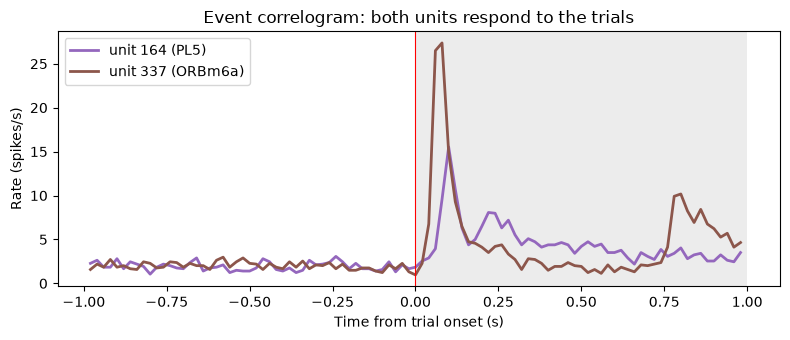

In [10]:
pair = [164, 337]
onsets = nap.Ts(t=trials.start)  # the trial onsets, as events

peth = nap.compute_eventcorrelogram(good[pair], onsets, binsize=0.02, windowsize=1.0, norm=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
for i, color in zip(pair, ["tab:purple", "tab:brown"]):
    ax.plot(peth.index, peth[i], color=color, lw=2, label=f"unit {i} ({good.location[i]})")
ax.axvspan(0, 1, color="gray", alpha=0.15, lw=0)
ax.axvline(0, color="red", lw=0.8)
ax.set(xlabel="Time from trial onset (s)", ylabel="Rate (spikes/s)",
       title="Event correlogram: both units respond to the trials")
ax.legend()
plt.tight_layout()
plt.show()

We compute the CCG of 164 → 337 **during the trials only** (the first 2 s after each onset), with
10 ms bins and a ±500 ms window. To find the part of the CCG that is due to the stimulus, we use the
**shift predictor**: we pair the spikes of unit 164 in trial $k$ with the spikes of unit 337 in
trial $k+1$. Both units still respond to the stimulus in each trial, but any precise interaction
between the two neurons is gone. What remains is the correlation **explained by the stimulus**.
We also compute the CCG in the inter-trial intervals (the 3 s before each trial).

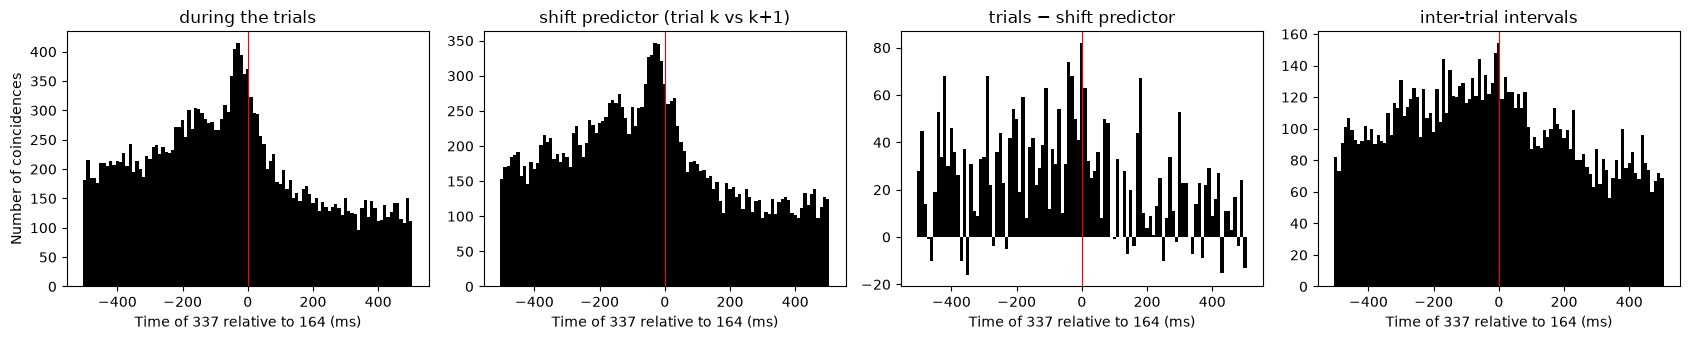

In [11]:
def trial_spikes(spikes, starts, before, after):
    """List of spike times relative to each start, between start + before and start + after."""
    return [spikes[(spikes >= s + before) & (spikes < s + after)] - s for s in starts]


def ccg_of_trials(ref_trials, target_trials, edges):
    """CCG summed over trials: only pairs of spikes from the same trial are counted."""
    counts = np.zeros(len(edges) - 1)
    for a, b in zip(ref_trials, target_trials):
        if len(a) and len(b):
            counts += np.histogram((b[None, :] - a[:, None]).ravel(), bins=edges)[0]
    return counts


edges = lag_bins(0.01, 0.5)  # 10 ms bins, ±500 ms
centers = (edges[:-1] + edges[1:]) / 2
spikes_a = trial_spikes(good[pair[0]].t, trials.start, 0, 2)  # 0 to 2 s after each onset
spikes_b = trial_spikes(good[pair[1]].t, trials.start, 0, 2)

ccg_trials = ccg_of_trials(spikes_a, spikes_b, edges)
ccg_shift = ccg_of_trials(spikes_a, spikes_b[1:] + spikes_b[:1], edges)  # trial k with trial k+1
ccg_iti = ccg_of_trials(trial_spikes(good[pair[0]].t, trials.start, -3, 0),
                        trial_spikes(good[pair[1]].t, trials.start, -3, 0), edges)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
panels = [(ccg_trials, "during the trials"), (ccg_shift, "shift predictor (trial k vs k+1)"),
          (ccg_trials - ccg_shift, "trials − shift predictor"), (ccg_iti, "inter-trial intervals")]
for ax, (y, title) in zip(axes, panels):
    ax.bar(centers * 1000, y, width=10, color="k")
    ax.axvline(0, color="red", lw=0.8)
    ax.set(title=title, xlabel=f"Time of {pair[1]} relative to {pair[0]} (ms)")
axes[0].set_ylabel("Number of coincidences")
plt.tight_layout()
plt.show()

During the trials, the CCG has a broad peak around 0, and the shift predictor has almost the same
peak: this correlation is explained by the stimulus, which makes both neurons fire at the same
times in every trial (the **signal correlation**). Once it is removed, only a small, noisy excess
is left (the **noise correlation**, from trial to trial). In the inter-trial intervals, without any
stimulus, the CCG still has a broad peak: the two units are also co-modulated at rest (brain state,
shared slow inputs). Note also the shape of the trial CCGs:
they decrease towards ±500 ms because, in a 2 s window, there are fewer pairs of spikes far apart in
time. The shift predictor has the same bias, so the difference removes it.

For **connectivity**, we care about the fast part of the CCG (a few ms), and the slow
co-modulations (stimulus, brain state) are a nuisance. The next section removes them.

## 5. Jitter correction and significance

### 5.1 The jitter-corrected CCG

To separate the fast interactions from the slow co-modulations, we **jitter** the spikes: we move
each spike of the target by a random amount, between −25 and +25 ms, and compute the CCG again.
Jittering keeps everything slower than ~25 ms (the rate changes, the slow co-modulations, the
responses to the stimulus) and destroys the precise timing at the scale of a few ms. We repeat it
40 times and average: this is the **jittered CCG**, the CCG expected *without* fast interactions.

Following [Siegle et al. (2021)](https://doi.org/10.1038/s41586-020-03171-x) and Matthieu's report,
the **jitter-corrected CCG** is the difference, divided by the geometric mean of the two firing
rates (so that pairs of fast and slow neurons can be compared):

$$ \mathrm{CCG}_{\text{corrected}, ij} = \frac{\mathrm{CCG}_{\text{real}, ij} - \mathrm{CCG}_{\text{jitter}, ij}}{\sqrt{\text{rate}_i \, \text{rate}_j}} $$

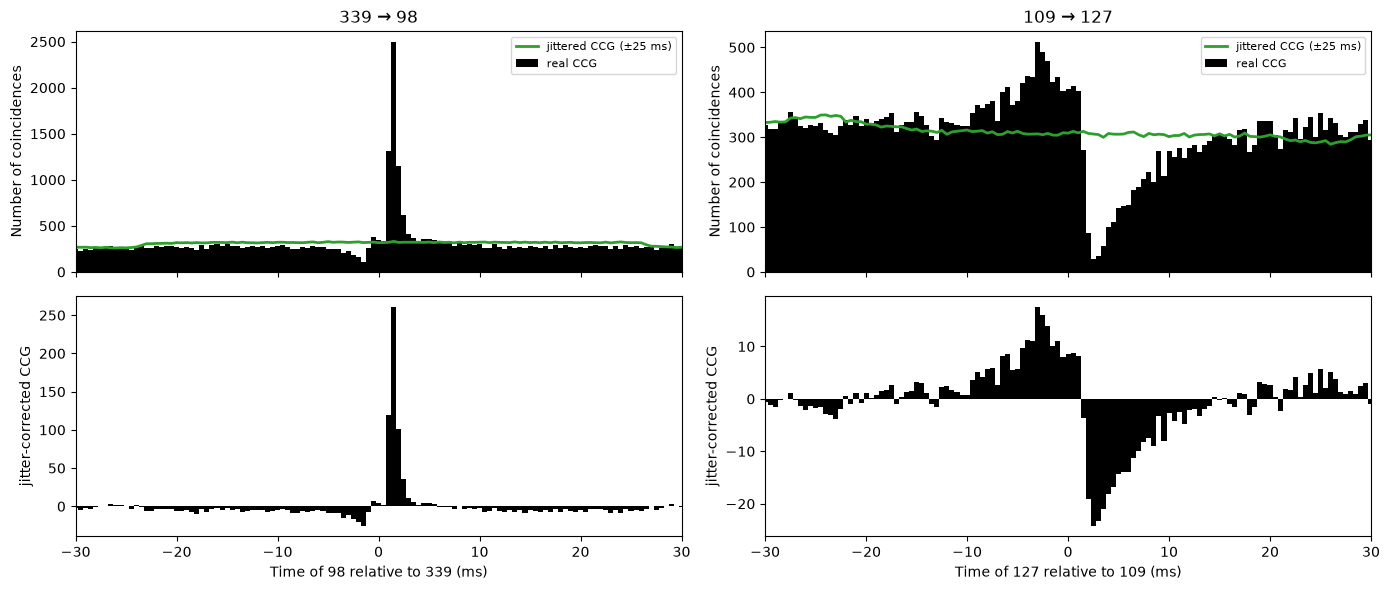

In [12]:
def ccg_counts(ref, target, edges):
    """CCG (number of coincidences) of target relative to ref, in the given bins."""
    return np.histogram(spike_time_differences(ref, target, edges[-1]), bins=edges)[0]


def jittered_ccg(ref, target, edges, jitter=0.025, n_rep=40):
    """Mean CCG after moving each target spike by a random time in ±jitter, over n_rep repetitions."""
    total = np.zeros(len(edges) - 1)
    for _ in range(n_rep):
        jittered = np.sort(target + rng.uniform(-jitter, jitter, size=len(target)))
        total += ccg_counts(ref, jittered, edges)
    return total / n_rep


edges = lag_bins(0.0005, 0.1)  # 0.5 ms bins, ±100 ms
centers = (edges[:-1] + edges[1:]) / 2
duration = good.time_support.tot_length()

corrected = {}  # (i, j) -> jitter-corrected CCG
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex=True)
for col, (i, j) in enumerate([(339, 98), (109, 127)]):
    real = ccg_counts(good[i].t, good[j].t, edges)
    jit = jittered_ccg(good[i].t, good[j].t, edges)
    corrected[(i, j)] = (real - jit) / np.sqrt(good.rate[i] * good.rate[j])

    axes[0, col].bar(centers * 1000, real, width=0.5, color="k", label="real CCG")
    axes[0, col].plot(centers * 1000, jit, color="tab:green", lw=2, label="jittered CCG (±25 ms)")
    axes[0, col].set(title=f"{i} → {j}", ylabel="Number of coincidences")
    axes[0, col].legend(fontsize=8)
    axes[1, col].bar(centers * 1000, corrected[(i, j)], width=0.5, color="k")
    axes[1, col].set(xlim=(-30, 30), xlabel=f"Time of {j} relative to {i} (ms)",
                     ylabel="jitter-corrected CCG")
plt.tight_layout()
plt.show()

The jittered CCG follows the slow shape of the real CCG, and the corrected CCG is flat at 0 except
for the fast part: the excitatory peak of 339 → 98 and the inhibitory trough of 109 → 127 stand out.

### 5.2 Is the connection significant?

We use the rule of Matthieu's report (adapted from Siegle et al., 2021):

1. the **baseline** is the corrected CCG far from 0, at lags between 50 and 100 ms on each side:
   there, no monosynaptic effect is expected. We measure its mean and standard deviation (SD);
2. we look in the window **[0.8 ms, 10 ms]** after 0: fast enough for a monosynaptic connection
   (one synapse, no intermediate neuron), and not at 0 (no synapse is instantaneous);
3. the connection is **excitatory** if at least **two consecutive bins** of this window are more than
   **7 SD above** the baseline mean, and **inhibitory** if at least two consecutive bins are more than
   **5 SD below** (troughs are smaller than peaks, so the threshold is lower).

Requiring two consecutive bins and such high thresholds keeps the false positives low, even when
we test thousands of pairs. We also require enough coincidences (at least 10 expected per bin in the
window): with very few spikes, a few empty bins in a row can look like a trough.

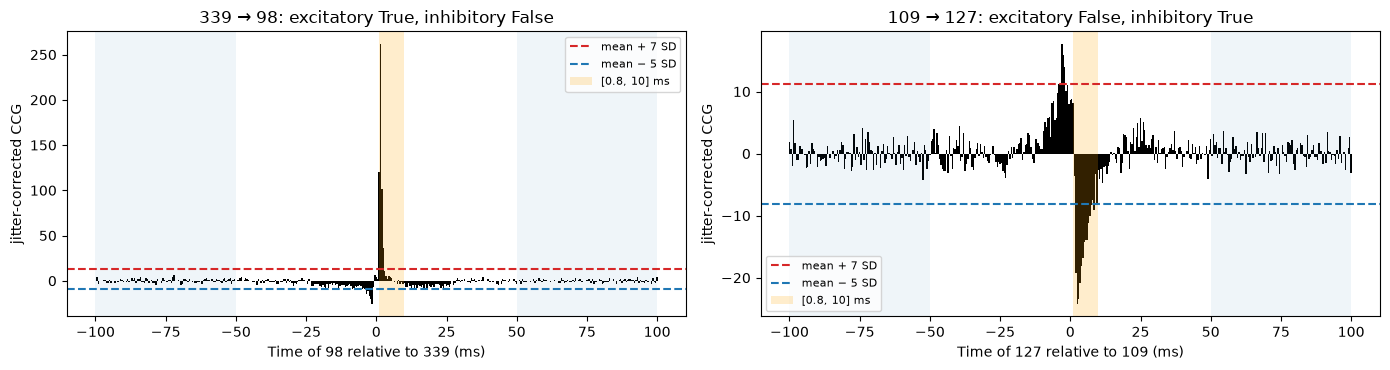

In [13]:
in_window = (centers > 0.0008) & (centers < 0.010)  # [0.8 ms, 10 ms]
flanks = np.abs(centers) > 0.050  # baseline: |lag| between 50 and 100 ms


def two_in_a_row(above):
    """True if at least two consecutive values are True."""
    return np.any(above[1:] & above[:-1])


fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, ((i, j), cc) in zip(axes, corrected.items()):
    mean, sd = cc[flanks].mean(), cc[flanks].std()
    high, low = mean + 7 * sd, mean - 5 * sd
    excitatory = two_in_a_row(cc[in_window] > high)
    inhibitory = two_in_a_row(cc[in_window] < low)

    ax.bar(centers * 1000, cc, width=0.5, color="k")
    ax.axhline(high, color="tab:red", ls="--", label="mean + 7 SD")
    ax.axhline(low, color="tab:blue", ls="--", label="mean − 5 SD")
    ax.axvspan(0.8, 10, color="orange", alpha=0.2, lw=0, label="[0.8, 10] ms")
    for side in (-1, 1):
        ax.axvspan(side * 50, side * 100, color="tab:blue", alpha=0.07, lw=0)  # baseline
    ax.set(title=f"{i} → {j}: excitatory {excitatory}, inhibitory {inhibitory}",
           xlabel=f"Time of {j} relative to {i} (ms)", ylabel="jitter-corrected CCG")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

(The light blue areas, at ±50–100 ms, are the baseline.)

### 5.3 Transmission probability

How strong is a connection? The **transmission probability** is the number of *extra* coincidences
in the window (real − jittered), divided by the number of spikes of the reference: the fraction of
the spikes of $i$ that make $j$ fire ([English et al., 2017](https://doi.org/10.1016/j.neuron.2017.09.033)).

In [14]:
i, j = 339, 98
real = ccg_counts(good[i].t, good[j].t, edges)
jit = jittered_ccg(good[i].t, good[j].t, edges)
extra = (real - jit)[in_window].sum()  # extra coincidences in [0.8, 10] ms
print(f"{i} → {j}: {extra:.0f} extra coincidences for {len(good[i])} spikes of {i}: "
      f"transmission probability {extra / len(good[i]):.3f}")

339 → 98: 4399 extra coincidences for 40270 spikes of 339: transmission probability 0.109


About one spike of 339 in ten is followed by an extra spike of 98: for a connection between two
neurons recorded extracellularly, this is a strong one.

### 5.4 Pitfalls: why a human still checks the CCGs

An automatic rule is never perfect. In Matthieu's report, every significant pair was checked by eye,
and several kinds of false positives came up (his Figure 3):

- **too few spikes**: the CCG is noisy, and a few empty or full bins can pass the threshold;
- a **broad increase** around 0: the CCG reflects a population of neurons firing together, not one
  connection;
- a **peak that starts before 0** and reaches its maximum after 0: the target may need several
  inputs, or the two neurons share an input;
- a **peak at 0 in an autocorrelogram-like shape**: one neuron recorded twice, on two parts of the
  probe, and not merged by the spike sorter (like 35 – 36);
- a **trough and a peak on each side of 0**: two neurons connected both ways (like 98 – 339), which is
  real, but must be counted as two connections with opposite signs.

**Question.** Change the thresholds (7 and 5 SD), the window ([0.8, 10] ms) or the jitter (±25 ms),
and see how the decisions change for the two pairs.

## 6. All pairs at once with SpikeInterface

To find all the putative connections of a recording, we need the CCGs of **all the pairs**. With
239 units, that is 239 × 238 = 56,882 ordered pairs. This is where
[SpikeInterface](https://spikeinterface.readthedocs.io) helps: it computes all the correlograms of a
sorting in one fast call (this is the basis of the countCCG pipeline).

### 6.1 From pynapple to a SpikeInterface sorting

SpikeInterface stores the output of a spike sorter as a **`Sorting`** object: for each unit, the
spike times as **sample indices** of the recording, plus the sampling frequency. Our NWB file only
has the spike times in seconds, so we convert them to samples at 30 kHz, the sampling frequency of
Neuropixels.

In [15]:
import spikeinterface as si
import spikeinterface.widgets as sw
from spikeinterface.postprocessing import compute_correlograms

sampling_frequency = 30_000.0  # Hz
unit_ids = list(good.keys())
sorting = si.NumpySorting.from_unit_dict(
    {i: np.round(good[i].t * sampling_frequency).astype("int64") for i in unit_ids},
    sampling_frequency=sampling_frequency)
sorting

/Users/pierre/Documents/Minischool_GDR2026_SpikeTrains/python/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NumpySorting: 239 units - 1 segments - 30.0kHz

### 6.2 All the correlograms, and three differences with pynapple

`compute_correlograms(sorting, window_ms, bin_ms)` computes the CCG of every pair of units and the
ACG of every unit. It returns an array of counts of shape (units × units × bins), and the bin edges
in ms. `window_ms` is the **total** width of the window: 100 ms means ±50 ms.

In [16]:
t0 = time.time()
ccgs, bins_ms = compute_correlograms(sorting, window_ms=100.0, bin_ms=1.0)
print(f"SpikeInterface: {time.time() - t0:.1f} s for all pairs, array of shape {ccgs.shape}")

SpikeInterface: 2.7 s for all pairs, array of shape (239, 239, 100)


A few seconds for all the pairs. (The first call also compiles the code with
[numba](https://numba.pydata.org): run the cell twice to see the real speed.) Before using these
CCGs, three differences with pynapple:

1. **The bins.** pynapple centers a bin on 0 (from −0.5 to 0.5 ms); SpikeInterface puts a bin
   **edge** at 0 (bins from −1 to 0 and from 0 to 1 ms).
2. **The direction.** In SpikeInterface, `ccgs[i, j]` counts the times of unit $i$ relative to unit
   $j$: the **opposite** of pynapple's column `(i, j)`. So the CCG "339 → 98" in our convention is
   `ccgs[98, 339]` (with the positions of the units in the array, given by `sorting.id_to_index`).
3. **The counts.** SpikeInterface returns numbers of coincidences; pynapple returns a rate
   (`norm=False`) or a ratio (`norm=True`).

To check that the counts agree, we count our spike time differences in the bins of SpikeInterface.

ccgs[98, 339] vs our counts, largest difference: 32 (out of 58284 coincidences)


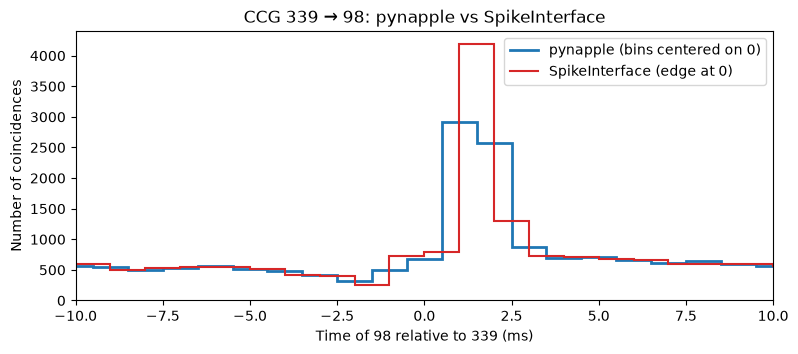

In [17]:
k339, k98 = sorting.id_to_index(339), sorting.id_to_index(98)  # positions of the units in the array
si_339_98 = ccgs[k98, k339]  # times of 98 relative to 339, in our convention

ours = ccg_counts(ref_all, target_all, bins_ms / 1000)
print("ccgs[98, 339] vs our counts, largest difference:", np.abs(si_339_98 - ours).max(),
      "(out of", ours.sum(), "coincidences)")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.stairs(counts_pynapple, lag_bins(0.001, 0.05) * 1000, color="tab:blue", lw=2,
          label="pynapple (bins centered on 0)")
ax.stairs(si_339_98, bins_ms, color="tab:red", lw=1.5, label="SpikeInterface (edge at 0)")
ax.set(xlim=(-10, 10), xlabel="Time of 98 relative to 339 (ms)", ylabel="Number of coincidences",
       title="CCG 339 → 98: pynapple vs SpikeInterface")
ax.legend()
plt.show()

The counts agree, up to a few coincidences that fall exactly on a bin edge (section 3). Always
check the conventions of a tool (the direction of the lag, where the bins are) before interpreting
a correlogram!

### 6.3 Jittering without jittering

Jittering 40 times means computing all the CCGs 41 times: for all the pairs of a recording, this
takes minutes. There is a shortcut. If each target spike moves by a random amount, uniform between
−25 and +25 ms, each coincidence of the CCG moves by the same random amount. So **on average**, the
jittered CCG is the real CCG **smoothed by a ±25 ms box** (a moving average over 101 bins of
0.5 ms). This is the idea of the convolution method of
[Stark & Abeles (2009)](https://doi.org/10.1016/j.jneumeth.2008.12.029), discussed in Matthieu's
report: no random numbers, a single CCG per pair. Let's check it on the pair 339 → 98.

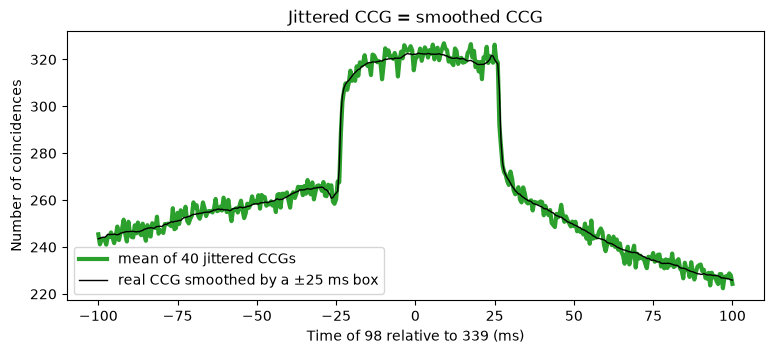

largest difference: 15.4 coincidences per bin


In [18]:
from scipy.ndimage import convolve1d

box = np.ones(101) / 101  # ±25 ms in 0.5 ms bins
wide_edges = lag_bins(0.0005, 0.125)  # compute the CCG up to ±125 ms, to smooth it up to ±100 ms
real_wide = ccg_counts(good[339].t, good[98].t, wide_edges)
smoothed = convolve1d(real_wide.astype(float), box, mode="nearest")[50:-50]  # back to ±100 ms

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(centers * 1000, jit, color="tab:green", lw=3, label="mean of 40 jittered CCGs")
ax.plot(centers * 1000, smoothed, color="k", lw=1, label="real CCG smoothed by a ±25 ms box")
ax.set(xlabel="Time of 98 relative to 339 (ms)", ylabel="Number of coincidences",
       title="Jittered CCG = smoothed CCG")
ax.legend()
plt.show()
print("largest difference:", np.abs(smoothed - jit).max().round(1), "coincidences per bin")

The two curves are the same, up to the randomness of the 40 jitters. Notice how the jitter spreads
the sharp excitatory peak into a plateau of ±25 ms: subtracting it removes the slow part of the CCG
and keeps the fast peak.

### 6.4 Scanning all the pairs

We now apply section 5 to all the pairs at once: the CCGs of all pairs with SpikeInterface
(0.5 ms bins, ±125 ms), the jittered CCGs by smoothing, the corrected CCGs, and the significance
rule. The arrays are (units × units × bins), and numpy applies each step to all the pairs together.
Remember the direction: `ccgs[a, b]` is unit `a` relative to unit `b`, so a significant peak after 0
in `ccgs[a, b]` is a connection **from `b` to `a`**.

In [19]:
def find_connections(sorting, duration, min_count=10):
    """Putative excitatory and inhibitory connections between all the units of a sorting.

    Returns two boolean matrices (units x units), and the z-score of the corrected CCGs:
    exc[a, b] is True for a putative excitatory connection from unit b to unit a."""
    real, bins = compute_correlograms(sorting, window_ms=250.0, bin_ms=0.5)  # ±125 ms
    real = real.astype(np.float32)  # float32: half the memory of float64, precise enough here
    lags = (bins[:-1] + bins[1:]) / 2  # bin centers, in ms
    jit = convolve1d(real, np.ones(101, dtype=np.float32) / 101, axis=2, mode="nearest")  # ±25 ms jitter
    keep = np.abs(lags) <= 100  # keep ±100 ms
    real, jit, lags = real[:, :, keep], jit[:, :, keep], lags[keep]

    n_spikes = np.array([len(sorting.get_unit_spike_train(u)) for u in sorting.unit_ids])
    rates = n_spikes / duration
    corrected = (real - jit) / np.sqrt(np.outer(rates, rates))[:, :, None]

    flanks = np.abs(lags) > 50  # baseline
    window = (lags > 0.8) & (lags < 10)  # [0.8, 10] ms
    sd = corrected[:, :, flanks].std(axis=2, keepdims=True)
    sd[sd == 0] = np.inf  # pairs without any coincidence
    z = (corrected - corrected[:, :, flanks].mean(axis=2, keepdims=True)) / sd

    enough = jit[:, :, window].mean(axis=2) >= min_count  # enough coincidences expected per bin
    above, below = z[:, :, window] > 7, z[:, :, window] < -5
    exc = (above[:, :, 1:] & above[:, :, :-1]).any(axis=2) & enough  # two bins in a row
    inh = (below[:, :, 1:] & below[:, :, :-1]).any(axis=2) & enough
    np.fill_diagonal(exc, False)  # no connection of a unit with itself
    np.fill_diagonal(inh, False)
    return exc, inh, z[:, :, window]


t0 = time.time()
exc, inh, z_window = find_connections(sorting, duration)
print(f"{time.time() - t0:.0f} s for {len(unit_ids) * (len(unit_ids) - 1)} ordered pairs")
print("putative excitatory connections:", exc.sum())
print("putative inhibitory connections:", inh.sum())

11 s for 56882 ordered pairs
putative excitatory connections: 76
putative inhibitory connections: 51


**Who connects to whom?** With the cell types, we can check that the connections make sense: the
excitatory connections should come mostly from RS units (pyramidal neurons), the inhibitory ones
from FS units (interneurons).

In [20]:
types = good.cell_type[unit_ids].values  # cell type of each unit, in the order of the sorting
for name, conn in [("excitatory", exc), ("inhibitory", inh)]:
    targets, sources = np.nonzero(conn)  # conn[a, b]: from b to a
    pairs, n = np.unique([f"{types[s]} → {types[t]}" for s, t in zip(sources, targets)],
                         return_counts=True)
    print(f"{name}:", ", ".join(f"{p}: {k}" for p, k in zip(pairs, n)))

excitatory: FS → FS: 12, RS → FS: 43, RS → RS: 21
inhibitory: FS → FS: 6, FS → RS: 28, RS → RS: 17


Most excitatory connections go from RS to FS units, and most inhibitory ones from FS to RS units,
as expected from pyramidal neurons and interneurons. (Some RS → RS "inhibitions" may be indirect,
through an interneuron that was not recorded.)

### 6.5 The connectivity matrix

We draw all the pairs as a **matrix**: one row per target unit, one column per source unit, with the
units **sorted by brain area and by depth**. The color is the largest z-score of the corrected CCG
in the window [0.8, 10] ms (red: excess, blue: deficit). On the right, only the significant
connections, as dots: excitatory in red, inhibitory in blue.

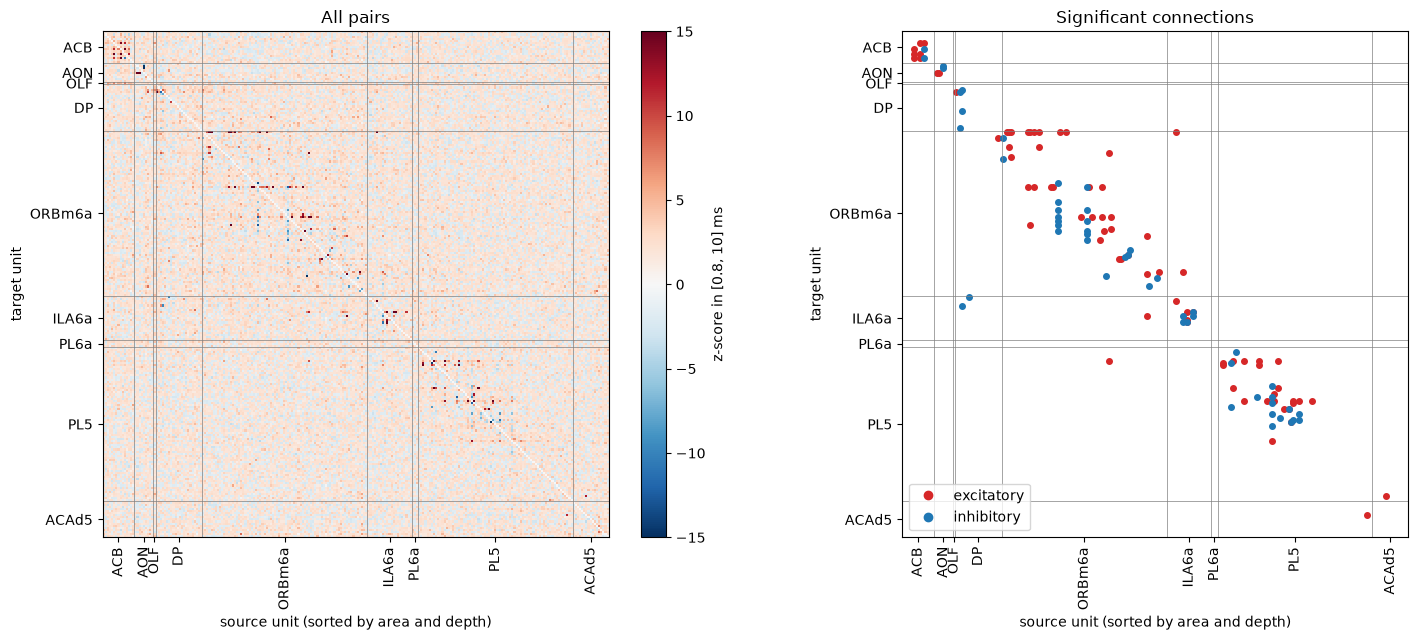

In [21]:
unit_area = good.location[unit_ids].values
unit_depth = good.depth[unit_ids].values
area_depth = {a: unit_depth[unit_area == a].mean() for a in set(unit_area)}  # mean depth of each area
order = np.lexsort((unit_depth, [area_depth[a] for a in unit_area]))  # areas along the probe, then depth
areas = good.location[unit_ids].values[order]
boundaries = np.flatnonzero(areas[1:] != areas[:-1]) + 0.5  # where the area changes
area_centers = [np.mean(np.flatnonzero(areas == a)) for a in dict.fromkeys(areas)]

strongest = np.where(np.abs(z_window.max(axis=2)) > np.abs(z_window.min(axis=2)),
                     z_window.max(axis=2), z_window.min(axis=2))  # largest excess or deficit
np.fill_diagonal(strongest, 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))
im = ax1.imshow(strongest[np.ix_(order, order)], cmap="RdBu_r", vmin=-15, vmax=15,
                interpolation="nearest")
fig.colorbar(im, ax=ax1, label="z-score in [0.8, 10] ms")
for a, b in zip(*np.nonzero(exc[np.ix_(order, order)])):
    ax2.plot(b, a, "o", color="tab:red", ms=4)
for a, b in zip(*np.nonzero(inh[np.ix_(order, order)])):
    ax2.plot(b, a, "o", color="tab:blue", ms=4)
ax2.plot([], [], "o", color="tab:red", label="excitatory")
ax2.plot([], [], "o", color="tab:blue", label="inhibitory")
ax2.set(xlim=(-0.5, len(order) - 0.5), ylim=(len(order) - 0.5, -0.5), aspect="equal")
ax2.legend(loc="lower left")
for ax, title in [(ax1, "All pairs"), (ax2, "Significant connections")]:
    for x in boundaries:  # lines between areas
        ax.axhline(x, color="gray", lw=0.5)
        ax.axvline(x, color="gray", lw=0.5)
    ax.set_xticks(area_centers, list(dict.fromkeys(areas)), rotation=90)
    ax.set_yticks(area_centers, list(dict.fromkeys(areas)))
    ax.set(xlabel="source unit (sorted by area and depth)", ylabel="target unit", title=title)
plt.tight_layout()
plt.show()

Most connections are **close to the diagonal**, inside each area: neurons recorded close to each
other are more often connected (and the CCG method only sees connections between neurons that are
both recorded, so near the probe). A few connections link different areas.

### 6.6 Plotting with SpikeInterface

SpikeInterface has ready-made plots for curation: `plot_autocorrelograms` and
`plot_crosscorrelograms` (a matrix of CCGs between a few units, with the ACGs on the diagonal).

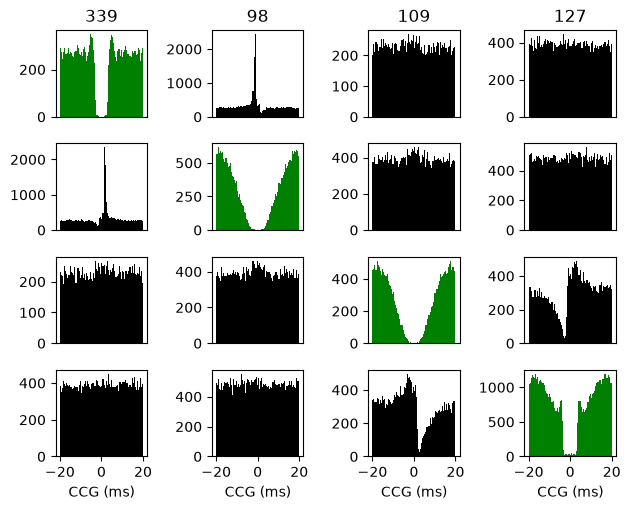

In [22]:
sw.plot_crosscorrelograms(sorting, unit_ids=[339, 98, 109, 127], window_ms=40.0, bin_ms=0.5)
plt.show()

In the matrix, the diagonal (in color) shows the autocorrelograms, and the other panels the
cross-correlograms between the units of each row and column. Find the excitatory peak between
339 and 98, and the trough between 109 and 127: on which side of 0 are they?

### 6.7 Advanced: does the network change with the task?

Functional connectivity can change with the state of the animal. In Matthieu's report, the
connections were found separately in each block of the task (section 0), and compared between
blocks with the **Jaccard index** of the two sets of connections $A$ and $B$:

$$ J = \frac{|A \cap B|}{|A \cup B|} $$

the number of connections found in both blocks, divided by the number found in at least one of
them: 1 for the same network, 0 for completely different ones. We restrict the spikes to each of the
blocks 1–4 (from 3 s before its first trial to 3 s after its last one) and run the scan again.

block 1: 6.7 min, 2 excitatory, 1 inhibitory
block 2: 13.8 min, 11 excitatory, 7 inhibitory
block 3: 6.9 min, 5 excitatory, 1 inhibitory
block 4: 6.8 min, 11 excitatory, 1 inhibitory


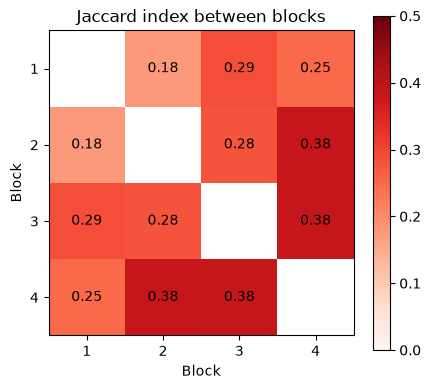

In [23]:
block_connections = {}
for b in [1, 2, 3, 4]:
    in_block = trials.Block == b
    period = nap.IntervalSet(start=trials.start[in_block].min() - 3, end=trials.end[in_block].max() + 3)
    block_sorting = si.NumpySorting.from_unit_dict(
        {i: np.round(good[i].restrict(period).t * sampling_frequency).astype("int64") for i in unit_ids},
        sampling_frequency=sampling_frequency)
    e, n, _ = find_connections(block_sorting, period.tot_length())
    block_connections[b] = e | n  # excitatory or inhibitory
    print(f"block {b}: {period.tot_length() / 60:.1f} min, {e.sum()} excitatory, {n.sum()} inhibitory")

jaccard = np.array([[np.sum(block_connections[a] & block_connections[b])
                     / max(np.sum(block_connections[a] | block_connections[b]), 1)
                     for b in block_connections] for a in block_connections])

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(np.where(np.eye(4, dtype=bool), np.nan, jaccard), cmap="Reds", vmin=0, vmax=0.5)
for a in range(4):
    for b in range(4):
        if a != b:
            ax.text(b, a, f"{jaccard[a, b]:.2f}", ha="center", va="center")
ax.set(xticks=range(4), xticklabels=[1, 2, 3, 4], yticks=range(4), yticklabels=[1, 2, 3, 4],
       xlabel="Block", ylabel="Block", title="Jaccard index between blocks")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Each block is short (7–14 minutes), so far fewer connections pass the significance rule than in the
whole session: only the strongest ones (only 3 in block 1). The highest similarities are between
blocks 2, 3 and 4 (up to 0.38), and the lowest between blocks 1 and 2, the same trend as in Matthieu's
report for this recording: after the first aversive stimulation (block 2), the network may stay in a
different state. But with so few connections, these numbers are fragile: they would need more
recordings, and a statistical test, to be conclusive.

### 6.8 Correlograms in spike sorting curation

In a full SpikeInterface workflow, the units come from a recording, and the correlograms are
computed as an extension of a `SortingAnalyzer` (`analyzer.compute("correlograms")`), together with
the waveforms, the templates and the quality metrics. Curation tools then use them, for example:

- the **refractory period violations** of each unit, from its ACG (a quality metric);
- the **automatic merging** of units: two units whose CCG looks like their ACGs (with a refractory
  gap at 0) and whose waveforms are similar are probably the same neuron, split in two;
- units that share many spikes at lag 0 (like 35 and 36) are flagged as **duplicates**.

See the spike sorting notebooks of this school (`notebooks_sorting/`) to run them on a recording.

**Questions.**

- Which unit receives the most excitatory connections? Draw its CCGs with its sources.
- Find the connections between different areas. Are they excitatory or inhibitory?
- Change `min_count` in `find_connections`, or the thresholds. How many connections are left in the
  blocks?